# League of Legends win predictor: data audit, cleaning and test-set reserve

**Dataset:** `lol_15min_all.csv`, one row per ranked solo/duo match on NA, captured at the 15:00 mark
(team totals for gold, XP, CS, kills, objectives, plus the champion and gold of each role).
**Target:** `blue_win` (1 = blue side won).

This notebook:

1. audits the raw file (types, missing values, duplicates, impossible values, internal consistency),
2. cleans it and logs every change,
3. **reserves a final test set before any exploration**, so nothing below is tuned on it,
4. documents every column in a data dictionary,
5. makes five interpreted plots (on the training split only), and
6. lists the data-quality and sampling concerns that limit what the model can claim.

`lol_10min_all.csv` holds the same matches at 10:00. This notebook covers the 15:00 file; the 10-vs-15
comparison lives in `lol_eda_10_vs_15.ipynb`.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e2dd"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2,
})
SEED = 42
DATA_DIR = Path("../data/training")   # run from the notebooks/ folder
ROLES = ["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"]
RANKS = ["IRON", "BRONZE", "SILVER", "GOLD", "PLATINUM", "EMERALD", "DIAMOND", "MASTER_PLUS"]

## 1. Load the raw file
`patch` is read as a string on purpose. As a number, patch `16.20` turns into `16.2`.

In [2]:
raw = pd.read_csv(DATA_DIR / "lol_15min_all.csv", dtype={"patch": str})
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"{raw.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory")
raw.drop(columns="player_hashes").head(3).T.head(20)

8,167 rows x 70 columns
11.0 MB in memory


,0,1,2
match_id,NA1_5647613124,NA1_5660330757,NA1_5645720671
rank_tier,IRON,BRONZE,SILVER
minute,15,15,15
game_start_ms,1790193544575,1792015859448,1789924011743
patch,16.19,16.2,16.18
game_duration_s,1121,1928,1807
blue_win,0,0,0
blue_gold,23590,23842,26861
blue_xp,29640,29692,31984
blue_level_sum,47,47,48


## 2. Audit

### 2a. Types, missing values, duplicates, constants

In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "nulls": raw.isna().sum(),
    "unique": raw.nunique(),
})
print("Total nulls:", int(raw.isna().sum().sum()))
print("Duplicate match_id:", raw.match_id.duplicated().sum())
print("Fully duplicated rows:", raw.duplicated().sum())
print("Match ids that are not NA1_<digits>:", (~raw.match_id.str.fullmatch(r"NA1_\d+")).sum())
print("Rank values outside the expected list:", (~raw.rank_tier.isin(RANKS)).sum())
print()
print("Constant columns (one unique value):")
display(audit[audit["unique"] == 1])
print("Raw patch values:", raw.patch.value_counts().to_dict())

Total nulls: 0
Duplicate match_id: 0
Fully duplicated rows: 0
Match ids that are not NA1_<digits>: 0
Rank values outside the expected list: 0

Constant columns (one unique value):


,dtype,nulls,unique
minute,int64,0,1
blue_heralds,int64,0,1
red_heralds,int64,0,1
heralds_diff,int64,0,1


Raw patch values: {'16.19': 3914, '16.2': 2662, '16.18': 1591}


No nulls, no duplicates, and no malformed ids. Three columns are constant: `minute` (always 15),
`blue_heralds` and `red_heralds` (always 0). The Rift Herald has not spawned by 15:00 in this data, so the
herald columns carry no information at this snapshot. They stay in the file for schema compatibility with
the live script but are excluded from modelling.

### 2b. Internal consistency

The file stores both raw team totals and blue-minus-red differences, and per-role gold alongside team gold.
Those must agree. Any mismatch means a bug in the data pipeline.

In [4]:
stats_ = ["gold", "xp", "level_sum", "cs", "kills", "assists", "towers", "plates",
          "dragons", "heralds", "voidgrubs", "wards"]
rows = []
for s in stats_:
    rows.append((f"{s}_diff == blue_{s} - red_{s}", int((raw[f"blue_{s}"] - raw[f"red_{s}"] != raw[f"{s}_diff"]).sum())))
for side in ["blue", "red"]:
    role_sum = raw[[f"{side}_{r}_gold" for r in ROLES]].sum(axis=1)
    rows.append((f"{side}: sum of role gold == team gold", int((role_sum != raw[f"{side}_gold"]).sum())))
for r in ROLES:
    rows.append((f"{r.lower()}_gold_diff == blue - red", int((raw[f"blue_{r}_gold"] - raw[f"red_{r}_gold"] != raw[f"{r.lower()}_gold_diff"]).sum())))

ph = raw.player_hashes.str.split(";")
rows.append(("player_hashes has exactly 10 entries", int((ph.str.len() != 10).sum())))
rows.append(("a player appears twice in one match", int((ph.map(lambda l: len(set(l))) < 10).sum())))
rows.append(("same champion on both teams in the same role", int(sum((raw[f"blue_{r}_champ"] == raw[f"red_{r}_champ"]).sum() for r in ROLES))))
rows.append(("a team with a repeated champion", int(sum((raw[[f"{s}_{r}_champ" for r in ROLES]].nunique(axis=1) < 5).sum() for s in ["blue", "red"]))))
rows.append(("blue_first_blood=1 but blue has 0 kills", int(((raw.blue_first_blood == 1) & (raw.blue_kills == 0)).sum())))
rows.append(("blue_first_blood=0 but red has 0 kills", int(((raw.blue_first_blood == 0) & (raw.red_kills == 0)).sum())))
rows.append(("games with zero kills (no first blood possible)", int(((raw.blue_kills + raw.red_kills) == 0).sum())))
display(pd.DataFrame(rows, columns=["check", "violations"]).set_index("check"))

,violations
check,
gold_diff == blue_gold - red_gold,0
xp_diff == blue_xp - red_xp,0
level_sum_diff == blue_level_sum - red_level_sum,0
cs_diff == blue_cs - red_cs,0
kills_diff == blue_kills - red_kills,0
assists_diff == blue_assists - red_assists,0
towers_diff == blue_towers - red_towers,0
plates_diff == blue_plates - red_plates,0
dragons_diff == blue_dragons - red_dragons,0


Every internal check passes with zero violations, so the derived columns can be trusted. Note that
`*_diff` columns are redundant with the raw totals; using both in a model would double count.

### 2c. Value ranges and plausibility

In [5]:
num = raw.select_dtypes("number").drop(columns=["minute", "game_start_ms"])
rng_tbl = num.describe(percentiles=[.01, .5, .99]).T[["min", "1%", "50%", "99%", "max"]].round(1)
team_cols = [f"blue_{s}" for s in stats_ if s != "heralds"] + ["game_duration_s"]
diff_cols = [f"{s}_diff" for s in stats_ if s != "heralds"]
display(rng_tbl.loc[team_cols + diff_cols])

,min,1%,50%,99%,max
blue_gold,17787.0,21737.0,27378.0,34181.1,39366.0
blue_xp,20327.0,26299.3,31855.0,36880.8,39440.0
blue_level_sum,37.0,43.0,48.0,53.0,55.0
blue_cs,224.0,301.0,438.0,547.0,587.0
blue_kills,0.0,3.0,12.0,25.0,37.0
blue_assists,0.0,1.0,11.0,28.0,43.0
blue_towers,0.0,0.0,0.0,3.0,6.0
blue_plates,0.0,2.0,8.0,20.0,34.0
blue_dragons,0.0,0.0,1.0,2.0,2.0
blue_voidgrubs,0.0,0.0,2.0,3.0,3.0


In [6]:
# Per-player values at 15:00, as a sanity check on team totals
lvl = pd.concat([raw.blue_level_sum, raw.red_level_sum]) / 5
print(f"Average champion level per team: min {lvl.min():.1f}, median {lvl.median():.1f}, max {lvl.max():.1f}")
role_gold = raw[[f"{s}_{r}_gold" for s in ["blue", "red"] for r in ROLES]].stack()
print(f"Single-player gold: min {role_gold.min():,}, median {role_gold.median():,.0f}, max {role_gold.max():,}")
print(f"Largest team kill count at 15:00: {max(raw.blue_kills.max(), raw.red_kills.max())}")

Average champion level per team: min 7.2, median 9.6, max 11.0
Single-player gold: min 2,204, median 5,423, max 12,870
Largest team kill count at 15:00: 37


All ranges are plausible for 15 minutes of play: no negatives, no impossible levels, and no gold outliers
that look like corrupt records. The extremes (a 16k gold gap, 37 kills) are real stomps, so they are kept.

### 2d. Timestamps, patch and game length

In [7]:
raw["start_time"] = pd.to_datetime(raw.game_start_ms, unit="ms")
patch_span = raw.groupby("patch").start_time.agg(["min", "max", "size"])
display(patch_span)
print("Collection window:", raw.start_time.min().date(), "to", raw.start_time.max().date())
print("match_id order matches time order:", raw.sort_values("match_id").start_time.is_monotonic_increasing)

short = raw[raw.game_duration_s < 900]
print(f"\nGames shorter than 15:00 that still have a '15:00' snapshot: {len(short)}")
display(short[["match_id", "game_duration_s", "blue_win", "gold_diff", "blue_kills", "red_kills"]])
print(f"Games ending between 15:00 and 16:00: {((raw.game_duration_s >= 900) & (raw.game_duration_s < 960)).sum()}")

,min,max,size
patch,,,
16.18,2026-09-14 22:42:20.540,2026-09-23 08:01:59.777,1591
16.19,2026-09-23 14:17:16.418,2026-10-07 08:31:33.495,3914
16.2,2026-10-07 12:28:52.188,2026-10-16 14:22:16.622,2662


Collection window: 2026-09-14 to 2026-10-16
match_id order matches time order: False

Games shorter than 15:00 that still have a '15:00' snapshot: 8


,match_id,game_duration_s,blue_win,gold_diff,blue_kills,red_kills
1412,NA1_5660114828,879,1,1452,13,13
1985,NA1_5649785243,856,0,-6264,2,9
3566,NA1_5652582175,848,0,-7845,7,16
4074,NA1_5655301093,859,0,-582,5,5
4777,NA1_5643096280,845,0,1521,8,7
5937,NA1_5660531298,878,1,7452,14,3
6167,NA1_5649371326,876,0,-3969,6,14
7829,NA1_5652024823,897,0,-9766,5,21


Games ending between 15:00 and 16:00: 305


**Finding:** a handful of matches ended before 15:00 (the shortest is 14:05), yet carry a 15:00 snapshot. No real
15:00 game state exists for them, so the row is the final frame, not the state at 15:00. They are removed in the
next section. Ranked games can only be surrendered from 15:00, so the games ending in the minutes right after
are early surrenders, which we keep because those are real outcomes (see Plot 2).

## 3. Clean

Cleaning is deliberately light, since the audit found a very clean file. Every step is logged in `clean_log`.

In [8]:
clean_log = []
df = raw.copy()

def step(name, mask_drop=None, note=""):
    global df
    before = len(df)
    if mask_drop is not None:
        df = df[~mask_drop(df)]
    clean_log.append((name, before - len(df), len(df), note))

# 1. Patch strings: make the minor version two digits so '16.2' reads as patch 16.20
df["patch"] = df.patch.where(df.patch.str.split(".").str[1].str.len() == 2, df.patch + "0")
step("Normalise patch to two-digit minor version", note="16.2 -> 16.20")

# 2. Rows whose '15:00' snapshot is not a real 15:00 state
step("Drop games that ended before 15:00", lambda d: d.game_duration_s < 900,
     "snapshot is the last frame, not the 15:00 state")

# 3. Order rows by time and give them a clear index
df = df.sort_values("game_start_ms").reset_index(drop=True)
step("Sort by game start time", note="needed for any time-based check later")

# 4. Types
df["rank_tier"] = pd.Categorical(df.rank_tier, categories=RANKS, ordered=True)
df["blue_win"] = df.blue_win.astype("int8")
df["blue_first_blood"] = df.blue_first_blood.astype("int8")
step("Cast rank_tier to ordered category, flags to int8")

# 5. Derived convenience columns (not model inputs)
df["game_minutes"] = df.game_duration_s / 60
df["n_champs_unique"] = df[[f"{s}_{r}_champ" for s in ["blue", "red"] for r in ROLES]].nunique(axis=1)
step("Add game_minutes, n_champs_unique")

display(pd.DataFrame(clean_log, columns=["step", "rows_removed", "rows_after", "note"]))
print(f"\nRaw {len(raw):,} -> clean {len(df):,} rows ({len(raw) - len(df)} removed, {(len(raw) - len(df)) / len(raw):.2%})")
print("Patches:", sorted(df.patch.unique(), key=lambda p: tuple(map(int, p.split(".")))))

,step,rows_removed,rows_after,note
0,Normalise patch to two-digit minor version,0,8167,16.2 -> 16.20
1,Drop games that ended before 15:00,8,8159,"snapshot is the last frame, not the 15:00 state"
2,Sort by game start time,0,8159,needed for any time-based check later
3,"Cast rank_tier to ordered category, flags to int8",0,8159,
4,"Add game_minutes, n_champs_unique",0,8159,



Raw 8,167 -> clean 8,159 rows (8 removed, 0.10%)
Patches: ['16.18', '16.19', '16.20']


What was **not** done, and why:

* **No outlier removal.** Large gold and kill gaps are real games and are exactly where the model must be confident.
* **No imputation.** There is nothing missing.
* **Constant columns kept in the file** (`minute`, heralds) so the schema matches the live script; they are excluded from `MODEL_FEATURES` below.

## 4. Reserve the final test set
The test set is carved out **now**, before plotting or feature choices, so none of the EDA can leak into it.
It is used once, at the very end, to report the final model's performance.

**How it is split:**

* 20% of matches, chosen at random but **stratified by `rank_tier` x `blue_win`** so both sets keep the
  same rank mix and win balance.
* Fixed seed (`42`), and a SHA-256 fingerprint of the held-out match ids is saved so the split can be verified later.
* The same player can appear in both train and test (see sampling concern 4). That is acknowledged
  rather than purged, since purging would remove almost all of the training data.

In [9]:
TEST_FRAC = 0.20
strata = df.rank_tier.astype(str) + "_" + df.blue_win.astype(str)

rng = np.random.default_rng(SEED)
test_idx = []
for _, idx in df.groupby(strata, observed=True).groups.items():
    idx = np.array(idx)
    n_test = int(round(len(idx) * TEST_FRAC))
    test_idx.extend(rng.choice(idx, size=n_test, replace=False))

is_test = df.index.isin(test_idx)
train, test = df[~is_test].copy(), df[is_test].copy()

assert set(train.match_id).isdisjoint(test.match_id), "train and test overlap"
assert len(train) + len(test) == len(df)
print(f"train: {len(train):,} matches   test (reserved): {len(test):,} matches ({len(test) / len(df):.1%})")

display(pd.DataFrame({"train": [train.blue_win.mean()], "test": [test.blue_win.mean()]}, index=["blue win rate"]).round(4))
mix = pd.concat({"train": train.rank_tier.value_counts(normalize=True),
                 "test": test.rank_tier.value_counts(normalize=True)}, axis=1).reindex(RANKS).round(3)
display(mix)
pm = pd.concat({"train": train.patch.value_counts(normalize=True),
                "test": test.patch.value_counts(normalize=True)}, axis=1).round(3)
display(pm)

train: 6,527 matches   test (reserved): 1,632 matches (20.0%)


,train,test
blue win rate,0.4923,0.4914


,train,test
rank_tier,,
IRON,0.125,0.125
BRONZE,0.124,0.124
SILVER,0.126,0.125
GOLD,0.125,0.125
PLATINUM,0.125,0.126
EMERALD,0.125,0.126
DIAMOND,0.125,0.125
MASTER_PLUS,0.125,0.125


,train,test
patch,,
16.19,0.484,0.460
16.20,0.325,0.331
16.18,0.191,0.209


In [10]:
# Sanity: do train and test look like the same population? (they should; the split is random)
chi_p = stats.chi2_contingency(pd.crosstab(is_test, df.patch))[1]
print(f"patch mix train vs test: chi-square p = {chi_p:.2f} (large p = no evidence of imbalance)")
ks_p = stats.ks_2samp(train.gold_diff, test.gold_diff).pvalue
print(f"gold_diff train vs test: KS p = {ks_p:.2f}")

# Save. The test file is named HOLDOUT so nobody opens it by accident.
train.to_csv(DATA_DIR / "lol_15min_train.csv", index=False)
test.to_csv(DATA_DIR / "lol_15min_test_HOLDOUT.csv", index=False)
fingerprint = hashlib.sha256("\n".join(sorted(test.match_id)).encode()).hexdigest()
(DATA_DIR / "lol_15min_test_HOLDOUT.sha256").write_text(fingerprint + "\n")
print("test-set fingerprint (sha256 of sorted match ids):", fingerprint[:16], "...")

patch mix train vs test: chi-square p = 0.15 (large p = no evidence of imbalance)
gold_diff train vs test: KS p = 0.24
test-set fingerprint (sha256 of sorted match ids): 0fa52389a9604099 ...


From here on, **only `train` is used.** To verify later that the test set was not modified, re-hash the
match ids in `lol_15min_test_HOLDOUT.csv` and compare with `lol_15min_test_HOLDOUT.sha256`.
Model selection should use cross-validation inside `train`; touch the holdout once.

## 5. Data dictionary
Grouped by purpose. "model_input" is the intended use: `yes` = candidate predictor, `no` = identifier,
target, or something that duplicates another column, `NO` = would leak the outcome.

In [11]:
D = []
def add(col, desc, dtype, unit, model, notes=""):
    D.append((col, desc, dtype, unit, model, notes))

add("match_id", "Riot match identifier (NA1_<number>)", "string", "id", "no", "unique key; ids are not in time order")
add("rank_tier", "Rank bracket the match was sampled from", "ordered category", "8 levels", "optional", "sampled ~equal per rank by design, so not the natural rank mix")
add("minute", "Snapshot time", "int", "minutes", "no", "constant = 15")
add("game_start_ms", "Game start", "int", "Unix epoch ms", "no", "")
add("start_time", "Game start as a timestamp (added at load)", "datetime", "UTC", "no", "")
add("patch", "Game version", "string", "major.minor", "optional", "16.18, 16.19, 16.20; kept as text")
add("game_duration_s", "Total length of the game", "int", "seconds", "NO", "LEAKS: only known after the game; auditing only")
add("game_minutes", "game_duration_s / 60 (added)", "float", "minutes", "NO", "leaks, as above")
add("player_hashes", "Anonymised ids of the 10 players, ';' separated", "string", "id", "no", "used only to measure repeat players")
add("blue_win", "TARGET: 1 if blue side won", "int8", "0/1", "target", "~49% positive")
add("n_champs_unique", "Distinct champions in the match (added)", "int", "count", "no", "always 10; consistency check")
for side in ["blue", "red"]:
    S = side.title()
    add(f"{side}_gold", f"{S} team total gold earned", "int", "gold", "via gold_diff", "")
    add(f"{side}_xp", f"{S} team total experience", "int", "xp", "via xp_diff", "")
    add(f"{side}_level_sum", f"{S} sum of the 5 champion levels", "int", "levels", "via level_sum_diff", "")
    add(f"{side}_cs", f"{S} minions and monsters killed", "int", "count", "via cs_diff", "")
    add(f"{side}_kills", f"{S} champion kills", "int", "count", "via kills_diff", "")
    add(f"{side}_assists", f"{S} kill assists", "int", "count", "via assists_diff", "")
    add(f"{side}_towers", f"{S} towers destroyed", "int", "count", "via towers_diff", "")
    add(f"{side}_plates", f"{S} tower plates taken", "int", "count", "via plates_diff", "")
    add(f"{side}_dragons", f"{S} dragons taken", "int", "count", "via dragons_diff", "0-2 in this data")
    add(f"{side}_heralds", f"{S} Rift Heralds taken", "int", "count", "no", "constant 0 at 15:00")
    add(f"{side}_voidgrubs", f"{S} Void Grubs taken", "int", "count", "via voidgrubs_diff", "0-3")
    add(f"{side}_wards", f"{S} wards placed", "int", "count", "via wards_diff", "weak signal; not available live")
    for r in ROLES:
        add(f"{side}_{r}_gold", f"Gold of the {side} {r.lower()} player", "int", "gold", "optional", "sums to team gold")
        add(f"{side}_{r}_champ", f"Champion played by {side} {r.lower()}", "string", "~170 values", "optional", "high-cardinality categorical")
add("blue_first_blood", "1 if blue got the first kill", "int8", "0/1", "yes", "")
for s, desc in [("gold", "gold"), ("xp", "experience"), ("level_sum", "level sum"), ("cs", "CS"),
                ("kills", "kills"), ("assists", "assists"), ("towers", "towers"), ("plates", "plates"),
                ("dragons", "dragons"), ("heralds", "heralds"), ("voidgrubs", "void grubs"), ("wards", "wards")]:
    add(f"{s}_diff", f"Blue minus red {desc}", "int", "blue - red", "yes" if s != "heralds" else "no",
        "positive = blue ahead" + ("; constant 0" if s == "heralds" else ""))
for r in ROLES:
    add(f"{r.lower()}_gold_diff", f"Blue minus red gold in the {r.lower()} lane", "int", "gold", "optional", "lane-level lead")

dictionary = pd.DataFrame(D, columns=["column", "description", "dtype", "unit", "model_input", "notes"])
print("Columns in data but not documented:", sorted(set(train.columns) - set(dictionary.column)) or "none")
print("Documented but not in data:", sorted(set(dictionary.column) - set(train.columns)) or "none")
dictionary.to_csv(DATA_DIR / "lol_15min_data_dictionary.csv", index=False)
with pd.option_context("display.max_colwidth", 80):
    display(dictionary)

Columns in data but not documented: none
Documented but not in data: none


,column,description,dtype,unit,model_input,notes
0,match_id,Riot match identifier (NA1_<number>),string,id,no,unique key; ids are not in time order
1,rank_tier,Rank bracket the match was sampled from,ordered category,8 levels,optional,"sampled ~equal per rank by design, so not the natural rank mix"
2,minute,Snapshot time,int,minutes,no,constant = 15
3,game_start_ms,Game start,int,Unix epoch ms,no,
4,start_time,Game start as a timestamp (added at load),datetime,UTC,no,
5,patch,Game version,string,major.minor,optional,"16.18, 16.19, 16.20; kept as text"
6,game_duration_s,Total length of the game,int,seconds,NO,LEAKS: only known after the game; auditing only
7,game_minutes,game_duration_s / 60 (added),float,minutes,NO,"leaks, as above"
8,player_hashes,"Anonymised ids of the 10 players, ';' separated",string,id,no,used only to measure repeat players
9,blue_win,TARGET: 1 if blue side won,int8,0/1,target,~49% positive


In [12]:
MODEL_FEATURES = ["gold_diff", "xp_diff", "level_sum_diff", "cs_diff", "kills_diff", "assists_diff",
                  "towers_diff", "plates_diff", "dragons_diff", "voidgrubs_diff", "wards_diff", "blue_first_blood"]
print("Candidate predictors:", MODEL_FEATURES)

Candidate predictors: ['gold_diff', 'xp_diff', 'level_sum_diff', 'cs_diff', 'kills_diff', 'assists_diff', 'towers_diff', 'plates_diff', 'dragons_diff', 'voidgrubs_diff', 'wards_diff', 'blue_first_blood']


## 6. Plots (training data only)

### Plot 1. Class balance and win rate by rank

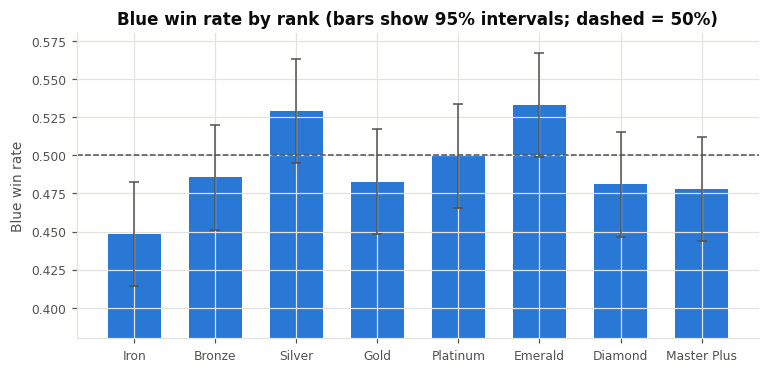

Overall blue win rate: 0.492  (3,213 of 6,527)


Is the win rate the same across ranks? chi-square p = 0.0127
Binomial test of overall rate vs 50%: p = 0.216


,mean,size,se
rank_tier,,,
IRON,0.449,816,0.017
BRONZE,0.486,809,0.018
SILVER,0.529,820,0.017
GOLD,0.483,816,0.017
PLATINUM,0.499,819,0.017
EMERALD,0.533,818,0.017
DIAMOND,0.481,813,0.018
MASTER_PLUS,0.478,816,0.017


In [13]:
g = train.groupby("rank_tier", observed=True).blue_win.agg(["mean", "size"]).reindex(RANKS)
se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
overall = train.blue_win.mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(g)), g["mean"], yerr=1.96 * se, color=BLUE, width=0.65, error_kw=dict(ecolor=INK2, capsize=3, lw=1))
ax.axhline(0.5, color=INK2, ls="--", lw=1)
ax.set_xticks(range(len(g)), [r.replace("_", " ").title() for r in RANKS])
ax.set(ylim=(0.38, 0.58), ylabel="Blue win rate",
       title="Blue win rate by rank (bars show 95% intervals; dashed = 50%)")
plt.show()

chi_p = stats.chi2_contingency(pd.crosstab(train.rank_tier, train.blue_win))[1]
print(f"Overall blue win rate: {overall:.3f}  ({train.blue_win.sum():,} of {len(train):,})")
print(f"Is the win rate the same across ranks? chi-square p = {chi_p:.4f}")
print(f"Binomial test of overall rate vs 50%: p = {stats.binomtest(int(train.blue_win.sum()), len(train)).pvalue:.3f}")
display(g.assign(se=se).round(3))

**Reading it.** The classes are balanced: blue wins 49.2% of games, which is not distinguishable from 50% (p = 0.22),
so accuracy is a fair metric next to AUC and no side adjustment is needed.

The ranks are *not* all the same, though (chi-square p = 0.013). Iron is the low outlier (44.9%), and Silver (52.9%)
and Emerald (53.3%) are high. There's no trend up or down the ladder, so this isn't a clean "blue is stronger at higher ranks"
effect, and with eight groups and one test it's suggestive rather than settled. The practical takeaway is to check whether `rank_tier`
adds anything in cross-validation, and to report holdout results per rank.

### Plot 2. How long games last: the survivorship filter

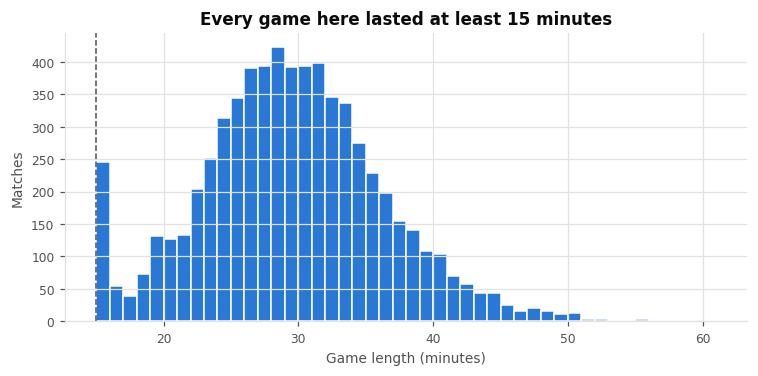

Median game: 29.4 min; 90% of games end by 38 min
Games over by 16:00 (early surrenders): 3.8%
Games over by 18:00: 5.2%

Gold gap at 15:00 >= 5k: 21.1% of games; 19.2% of them end before 18:00
Gold gap < 5k:           78.9% of games; 1.5% of them end before 18:00


In [14]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(train.game_minutes, bins=np.arange(15, 62, 1), color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(15, color=INK2, ls="--", lw=1)
ax.set(xlabel="Game length (minutes)", ylabel="Matches", title="Every game here lasted at least 15 minutes")
plt.show()

print(f"Median game: {train.game_minutes.median():.1f} min; 90% of games end by {train.game_minutes.quantile(.9):.0f} min")
print(f"Games over by 16:00 (early surrenders): {(train.game_minutes < 16).mean():.1%}")
print(f"Games over by 18:00: {(train.game_minutes < 18).mean():.1%}")

big = train.gold_diff.abs() >= 5000
print(f"\nGold gap at 15:00 >= 5k: {big.mean():.1%} of games; {(train[big].game_minutes < 18).mean():.1%} of them end before 18:00")
print(f"Gold gap < 5k:           {(~big).mean():.1%} of games; {(train[~big].game_minutes < 18).mean():.1%} of them end before 18:00")

**Reading it.** The histogram starts at 15 minutes because only games still running at 15:00 are in the data (and we dropped the few that weren't).
The spike right after 15:00, when surrender unlocks, holds 3.8% of games ending before 16:00. Those games are lopsided: when one team
is 5k+ gold ahead at 15:00 (21% of games), 19% of them are over before 18:00, compared with 1.5% of games with a smaller gap. They're real
outcomes, so they stay in, but they make 15:00 easier to predict than the average moment in a game. Accuracy here applies to "games that reach 15:00",
not to the whole match.

### Plot 3. Gold lead at 15:00 against win rate

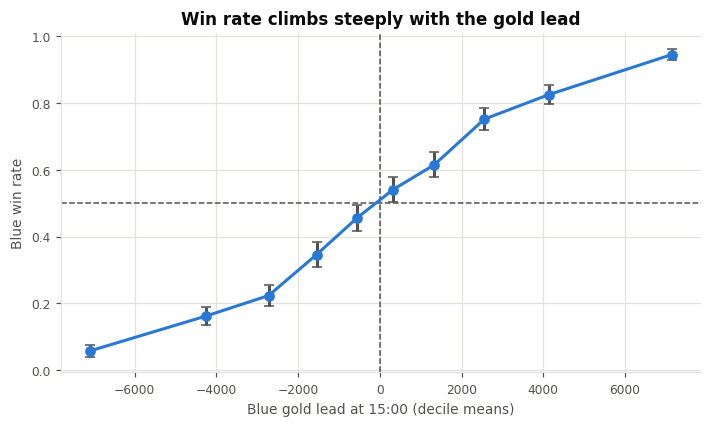

,gold,win,n,se
gold_diff,,,,
"(-16450.001, -5202.4]",-7086.386,0.058,653,0.009
"(-5202.4, -3384.8]",-4253.028,0.162,653,0.014
"(-3384.8, -2091.0]",-2724.848,0.224,653,0.016
"(-2091.0, -1021.0]",-1551.374,0.346,653,0.019
"(-1021.0, -129.0]",-555.940,0.456,653,0.019
"(-129.0, 784.6]",319.627,0.541,651,0.020
"(784.6, 1909.0]",1325.817,0.615,654,0.019
"(1909.0, 3282.0]",2558.853,0.752,653,0.017
"(3282.0, 5056.4]",4127.071,0.825,651,0.015


In [15]:
q = pd.qcut(train.gold_diff, 10)
curve = train.groupby(q, observed=True).agg(gold=("gold_diff", "mean"), win=("blue_win", "mean"), n=("blue_win", "size"))
curve["se"] = np.sqrt(curve.win * (1 - curve.win) / curve.n)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.errorbar(curve.gold, curve.win, yerr=1.96 * curve.se, fmt="o-", color=BLUE, ecolor=INK2, capsize=3)
ax.axhline(0.5, color=INK2, ls="--", lw=1); ax.axvline(0, color=INK2, ls="--", lw=1)
ax.set(xlabel="Blue gold lead at 15:00 (decile means)", ylabel="Blue win rate",
       title="Win rate climbs steeply with the gold lead")
plt.show()
display(curve.round(3))

**Reading it.** This is the main signal. Blue wins 5.8% of games from the most-behind decile (average deficit about 7.1k gold) and 94.5% from the
most-ahead decile (about +7.1k). Near even the win rate is near 50%. In the middle, each extra 1,000 gold of lead is worth roughly 8-11 points of win
rate, and the curve flattens in the tails (about 4 points per 1,000 gold beyond +4k) because those games are close to decided. The S shape is
what a logistic regression expects. A 15:00 lead is not a guarantee: a team about 2.5k ahead still loses roughly one game in four.

### Plot 4. Which features carry signal, and how redundant they are

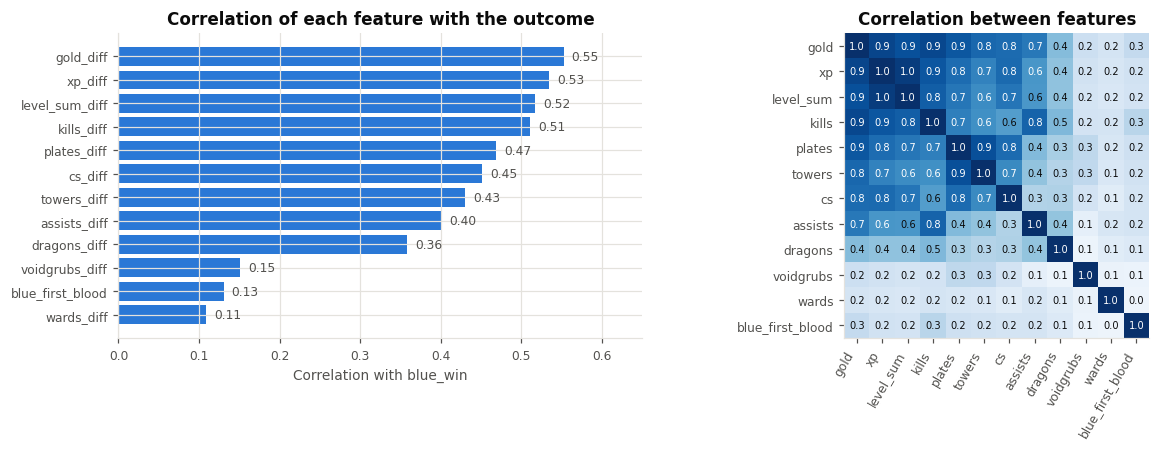

Correlation with win: {'gold_diff': 0.55, 'xp_diff': 0.53, 'level_sum_diff': 0.52, 'kills_diff': 0.51, 'plates_diff': 0.47, 'cs_diff': 0.45, 'towers_diff': 0.43, 'assists_diff': 0.4, 'dragons_diff': 0.36, 'voidgrubs_diff': 0.15, 'blue_first_blood': 0.13, 'wards_diff': 0.11}
gold vs xp: 0.92 | gold vs kills: 0.91


In [16]:
corr_t = train[MODEL_FEATURES + ["blue_win"]].corr()
signal = corr_t["blue_win"].drop("blue_win").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.15]})
axes[0].barh(signal.index, signal.values, color=BLUE)
axes[0].set(xlabel="Correlation with blue_win", title="Correlation of each feature with the outcome")
for y, v in enumerate(signal.values):
    axes[0].text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color=INK2)
axes[0].set_xlim(0, 0.65)

order = ["gold_diff", "xp_diff", "level_sum_diff", "kills_diff", "plates_diff", "towers_diff", "cs_diff",
         "assists_diff", "dragons_diff", "voidgrubs_diff", "wards_diff", "blue_first_blood"]
cm = train[order].corr()
axes[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(len(order)), [o.replace("_diff", "") for o in order], rotation=60, ha="right")
axes[1].set_yticks(range(len(order)), [o.replace("_diff", "") for o in order])
axes[1].grid(False)
for i in range(len(order)):
    for j in range(len(order)):
        axes[1].text(j, i, f"{cm.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                     color="white" if cm.iloc[i, j] > 0.6 else INK)
axes[1].set_title("Correlation between features")
fig.tight_layout()
plt.show()

print("Correlation with win:", signal.sort_values(ascending=False).round(2).to_dict())
print("gold vs xp:", round(cm.loc["gold_diff", "xp_diff"], 2), "| gold vs kills:", round(cm.loc["gold_diff", "kills_diff"], 2))

**Reading it.** Gold (0.55), XP (0.53), level (0.52) and kills (0.51) track the outcome most, but they are strongly correlated with each other
(gold vs XP is 0.92, gold vs kills 0.91). They are largely different ways of measuring "who is ahead", so adding all of them improves a model
less than their individual correlations suggest, and the coefficients on such features are unstable. Dragons (0.36), void grubs (0.15) and first
blood (0.13) are less tied to gold, so they may add information that gold does not. Wards (0.11) is the weakest. Plan on regularisation, or
choose a few representatives from the gold/XP/kills block.

### Plot 5. Is the 15:00 snapshot equally informative at every rank?

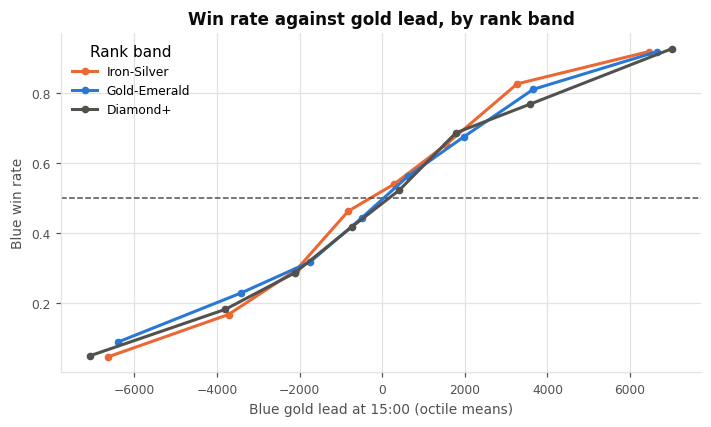

,gold_diff_std,corr_with_win,matches
rank_band,,,
Iron-Silver,3948.704,0.562,2445
Gold-Emerald,3947.862,0.538,2453
Diamond+,4238.558,0.559,1629


In [17]:
train["rank_band"] = pd.cut(train.rank_tier.cat.codes, [-1, 2, 5, 7], labels=["Iron-Silver", "Gold-Emerald", "Diamond+"])
fig, ax = plt.subplots(figsize=(7.5, 4))
colors = {"Iron-Silver": ORANGE, "Gold-Emerald": BLUE, "Diamond+": INK2}
bands = []
for band, g in train.groupby("rank_band", observed=True):
    q = pd.qcut(g.gold_diff, 8)
    c = g.groupby(q, observed=True).agg(gold=("gold_diff", "mean"), win=("blue_win", "mean"))
    ax.plot(c.gold, c.win, "o-", color=colors[band], label=band, ms=4)
    bands.append((band, g.gold_diff.std(), np.corrcoef(g.gold_diff, g.blue_win)[0, 1], len(g)))
ax.axhline(0.5, color=INK2, ls="--", lw=1)
ax.set(xlabel="Blue gold lead at 15:00 (octile means)", ylabel="Blue win rate",
       title="Win rate against gold lead, by rank band")
ax.legend(title="Rank band")
plt.show()
display(pd.DataFrame(bands, columns=["rank_band", "gold_diff_std", "corr_with_win", "matches"]).round(3).set_index("rank_band"))

**Reading it.** The curves for the three rank bands sit close together, so a given gold lead means about the same thing at every rank, and one
model across ranks is reasonable. The spread of gold leads (about 3.9k to 4.2k) and the correlation with the win (0.54 to 0.56) are similar in all
three bands. Higher-rank games are not noticeably less snowbally at 15:00. The caveat is sample size: with 1,600 to 2,500 matches per band, small
differences between bands (such as Diamond+ having slightly wider gold gaps) can't be told apart from noise.

## 7. Data-quality and sampling concerns

**Data quality.** The file is unusually clean, so these are narrow:

| # | Concern | Evidence | Handling |
|---|---|---|---|
| Q1 | Rows whose "15:00" snapshot is not a 15:00 state | Games that ended before 15:00 (section 2d) | Dropped |
| Q2 | Patch stored as a number loses its trailing zero (16.20 -> 16.2) | Raw `patch` column | Read as text, normalised |
| Q3 | Constant columns (`minute`, heralds) | 1 unique value | Kept in file, excluded from features |
| Q4 | Redundant columns: `*_diff` duplicates the raw totals; role gold sums to team gold | Section 2b | One representation per model |
| Q5 | `game_duration_s` is known only after the game | Definition | Never used as a predictor |
| Q6 | `wards_diff` is defined differently in the 10-min file, so it can't be compared across files | See `lol_eda_10_vs_15.ipynb` | Don't pool the two files |
| Q7 | Gold, XP and plates are not available from the live game API | Project README / earlier notebook | A live model can't use them; evaluate a live-feature model separately |

**Sampling concerns.** These limit what conclusions generalise, and cannot be fixed by cleaning:

1. **Rank is stratified, not natural.** Each rank was sampled to about 1,000 games. In NA most real ranked games are
   in the middle of the ladder and Master+ is a tiny fraction. Overall metrics are therefore not what a typical player
   would see. Report them per rank or reweight.
2. **Survivorship at 15:00.** Only games that reached 15:00 are included (Plot 2). Accuracy applies to "games still running at 15:00".
3. **One region, about one month, three patches.** NA only, mid-September to mid-October 2026, patches 16.18-16.20. Win rates by champion or
   objective can shift every patch, and other regions play differently. Retrain as patches change.
4. **Repeated players.** The 81,670 player slots are filled by about 58,000 unique players, and some appear in about 100 matches. Matches are not
   fully independent, and a random train/test split leaves the same player on both sides (nearly every train match shares a
   player with some test match, so purging is not feasible). Player ids are not model inputs, so the leakage risk is low, but
   cross-validation scores may be mildly optimistic. A temporal holdout is the stricter option if this matters.
5. **Champion coverage is uneven.** About 170 champions appear, but a champion x role pair can have very few games.
   Champion-level conclusions will need shrinkage or a minimum sample.
6. **Rank provenance is undocumented.** The collection script that assigned `rank_tier` is not in this repository, so treat it as a bracket label for the match, not as each player's rank.
7. **Ranked solo/duo only.** No normals, flex or pro play, so don't apply the model to other queues.
8. **Unobserved selection.** The collection and match-selection code is not in this repository, so any filtering applied
   upstream (failed API lookups, remakes, which players were used as seeds) is unknown.

**What this means for modelling.** Use cross-validation on `train` only; report the final score on the holdout once, ideally
per rank; treat gold/XP/kills as one correlated block; and don't read the result as accuracy for the live game state unless
the model is restricted to live-available features.

## 8. Outputs written by this notebook
All files are written to `data/training/`.

| File | Contents |
|---|---|
| `lol_15min_train.csv` | cleaned training split (80%) |
| `lol_15min_test_HOLDOUT.csv` | **reserved test split (20%). Do not open until the final evaluation.** |
| `lol_15min_test_HOLDOUT.sha256` | fingerprint of the held-out match ids |
| `lol_15min_data_dictionary.csv` | the data dictionary above |